# How a TTS model turns context into pronunciation

## 1. Research question and hypothesis

**Question.** When a pretrained text-to-speech (TTS) model reads a heteronym (one spelling, two pronunciations, e.g. *read* /ɹiːd/ vs /ɹɛd/), does the surrounding context make it produce the intended pronunciation? And can the intended pronunciation be decoded from the model's internal text representations?

**Hypotheses (set before running the main experiment).**
- H1: The model produces the context-appropriate pronunciation more often than a context-blind strategy would. A model that always says the same thing scores 50% on a balanced pair set.
- H2: Accuracy differs between heteronyms. Some words get resolved by context, while for others the model falls back to one default pronunciation.
- H3: If the text encoder uses context, a linear probe trained on encoder states at the target word should predict the intended pronunciation above chance in later layers. At the non-contextual input layer it should sit near chance.

This is a behavioural and representational study of an existing model. Nothing is trained except tiny linear probes.

## 2. Environment and model selection

**Hardware:** local CPU only (Intel Core Ultra 7 155H, 32 GB RAM, no CUDA GPU). Every model used here runs on CPU.

**Why SpeechT5.** The research question only makes sense if the *neural network* sees the ambiguous spelling. Many popular TTS systems run a grapheme-to-phoneme (G2P) front-end first, and that front-end already decides between /ɹiːd/ and /ɹɛd/:
- Kokoro (Apache-2.0) uses the `misaki` G2P front-end.
- Typical Piper and Coqui VITS English voices feed eSpeak phonemes into the network.
- `kakao-enterprise/vits-ljs` phonemizes its input as well.

In those systems, a heteronym error is a front-end error, not something the network learned from context. The candidates were screened from their model cards and documented pipelines. Only SpeechT5 was run.

[`microsoft/speecht5_tts`](https://huggingface.co/microsoft/speecht5_tts) (MIT licence) reads **raw characters**. Its tokenizer splits text into single characters with no phoneme dictionary, so the network itself must turn spelling plus context into sound.

Its structure is easy to probe:
- a 12-layer bidirectional Transformer **text encoder** (hidden size 768);
- an autoregressive decoder that predicts mel-spectrogram frames while cross-attending to the encoder output;
- a separate HiFi-GAN vocoder ([`microsoft/speecht5_hifigan`](https://huggingface.co/microsoft/speecht5_hifigan), MIT) that turns the mel-spectrogram into audio.

`facebook/mms-tts-eng` (VITS, also character input) was the fallback. It was not needed, and its CC-BY-NC licence is more restrictive.

**Voice:** the CMU ARCTIC speaker `slt` x-vector from [`Matthijs/cmu-arctic-xvectors`](https://huggingface.co/datasets/Matthijs/cmu-arctic-xvectors) (MIT). This is the standard example voice for SpeechT5.

**Evaluator (independent of the TTS model):** [`facebook/wav2vec2-lv-60-espeak-cv-ft`](https://huggingface.co/facebook/wav2vec2-lv-60-espeak-cv-ft) (Apache-2.0), a CTC model that outputs a *phoneme* sequence rather than words. We use phonemes because ordinary ASR would print "read" for both pronunciations. Torchaudio's `MMS_FA` CTC forced aligner supplies word time stamps so the target word can be found in the phoneme sequence.

All Hugging Face downloads are pinned to exact revisions.

In [1]:
import io, json, os, re, shutil, zipfile, platform, warnings, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf
import torch, torchaudio, transformers, sklearn, huggingface_hub
from scipy.stats import binomtest
from sklearn.neighbors import NearestCentroid
from IPython.display import Audio, display
from huggingface_hub import hf_hub_download
from transformers import SpeechT5Processor, SpeechT5ForTextToSpeech, SpeechT5HifiGan, Wav2Vec2FeatureExtractor, Wav2Vec2ForCTC

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
huggingface_hub.utils.disable_progress_bars()
pd.set_option("display.width", 200, "display.max_colwidth", 80, "display.max_rows", 200)

TTS_ID, TTS_REV = "microsoft/speecht5_tts", "30fcde30f19b87502b8435427b5f5068e401d5f6"
VOC_ID, VOC_REV = "microsoft/speecht5_hifigan", "bb6f429406e86a9992357a972c0698b22043307d"
XVEC_ID, XVEC_REV = "Matthijs/cmu-arctic-xvectors", "5c1297a9eb6c91714ea77c0d4ac5aca9b6a952e5"
PHONE_ID, PHONE_REV = "facebook/wav2vec2-lv-60-espeak-cv-ft", "ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4"
CMUDICT_URL = "https://raw.githubusercontent.com/cmusphinx/cmudict/74790861f652b15e4ac49015a90074ad62a27690/cmudict.dict"
SPEAKER = "cmu_us_slt_arctic-wav-arctic_a0508"
SEEDS = [0, 1, 2]
SR = 16000
AUDIO_DIR = "audio_cache"  # generated wavs (re-creatable, not committed)
os.makedirs(AUDIO_DIR, exist_ok=True)
os.makedirs("results", exist_ok=True)

print("python", platform.python_version(), "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| transformers", transformers.__version__, "| sklearn", sklearn.__version__, "| threads", torch.get_num_threads())

python 3.12.10 | torch 2.14.1+cpu | torchaudio 2.11.0+cpu | transformers 5.20.2 | sklearn 1.9.1 | threads 16


In [2]:
processor = SpeechT5Processor.from_pretrained(TTS_ID, revision=TTS_REV)
tts = SpeechT5ForTextToSpeech.from_pretrained(TTS_ID, revision=TTS_REV).eval()
vocoder = SpeechT5HifiGan.from_pretrained(VOC_ID, revision=VOC_REV).eval()

xvec_zip = zipfile.ZipFile(hf_hub_download(XVEC_ID, "spkrec-xvect.zip", repo_type="dataset", revision=XVEC_REV))
speaker = torch.tensor(np.load(io.BytesIO(xvec_zip.read(f"spkrec-xvect/{SPEAKER}.npy")))).unsqueeze(0)

phone_fe = Wav2Vec2FeatureExtractor.from_pretrained(PHONE_ID, revision=PHONE_REV)
phone_model = Wav2Vec2ForCTC.from_pretrained(PHONE_ID, revision=PHONE_REV).eval()
phone_vocab = {i: p for p, i in json.load(open(hf_hub_download(PHONE_ID, "vocab.json", revision=PHONE_REV), encoding="utf8")).items()}
aligner = torchaudio.pipelines.MMS_FA.get_model(with_star=False).eval()
align_dict = torchaudio.pipelines.MMS_FA.get_dict(star=None)

print("encoder layers:", tts.config.encoder_layers, "| hidden size:", tts.config.hidden_size, "| speaker x-vector:", tuple(speaker.shape))

encoder layers: 12 | hidden size: 768 | speaker x-vector: (1, 512)


## 3. Feasibility checks

**3a. What the network actually receives.** If the tokenizer produced phonemes, the experiment would be pointless. It produces characters, with `▁` marking word boundaries. Token `k+1` corresponds exactly to character `k` of the sentence (token 0 is a leading `▁`, the last token is `</s>`). Later, this mapping lets us find a word's encoder states by its character span.

In [3]:
example = "I read the book yesterday."
ids = processor(text=example, return_tensors="pt")["input_ids"]
tokens = processor.tokenizer.convert_ids_to_tokens(ids[0])
print(tokens)
print("unknown tokens:", processor.tokenizer.unk_token_id in ids[0].tolist(),
      "| token k+1 == char k:", "".join(tokens[1:-1]).replace("▁", " ") == example)

['▁', 'I', '▁', 'r', 'e', 'a', 'd', '▁', 't', 'h', 'e', '▁', 'b', 'o', 'o', 'k', '▁', 'y', 'e', 's', 't', 'e', 'r', 'd', 'a', 'y', '.', '</s>']
unknown tokens: False | token k+1 == char k: True


Transformers 5.x rebuilds the sinusoidal positional-encoding buffers at load time instead of reading them from the checkpoint. That causes a load warning (silenced above). The check below confirms the rebuilt buffers match the checkpoint, so the model behaves as originally released.

In [4]:
ckpt = torch.load(hf_hub_download(TTS_ID, "pytorch_model.bin", revision=TTS_REV), map_location="cpu", weights_only=True)
for name, module in [("encoder", tts.speecht5.encoder.prenet), ("decoder", tts.speecht5.decoder.prenet)]:
    diff = (ckpt[f"speecht5.{name}.prenet.encode_positions.pe"] - module.encode_positions.pe).abs().max().item()
    print(f"{name} positional encoding: max |checkpoint - rebuilt| = {diff:.1e}")
del ckpt

encoder positional encoding: max |checkpoint - rebuilt| = 6.1e-05
decoder positional encoding: max |checkpoint - rebuilt| = 1.2e-04


**3b. Audio generation.** We use `generate_speech` with its default settings (stop threshold 0.5, `minlenratio=0`, `maxlenratio=20`). The SpeechT5 decoder pre-net keeps dropout switched on at inference (a Tacotron-2 design choice), so the output is **random**. A fixed seed gives an identical waveform, and different seeds give slightly different speech. For that reason every sentence is generated with 3 fixed seeds.

In [5]:
def synthesize(text, seed):
    torch.manual_seed(seed)
    ids = processor(text=text, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        return tts.generate_speech(ids, speaker, vocoder=vocoder).numpy()

w_a, w_b, w_c = synthesize(example, 0), synthesize(example, 0), synthesize(example, 1)
print(f"{len(w_a) / SR:.2f} s | finite: {np.isfinite(w_a).all()} | peak: {np.abs(w_a).max():.2f}")
print("same seed -> identical audio:", np.array_equal(w_a, w_b), "| different seed -> identical audio:", len(w_a) == len(w_c) and np.allclose(w_a, w_c))
display(Audio(w_a, rate=SR))

1.57 s | finite: True | peak: 0.27
same seed -> identical audio: True | different seed -> identical audio: False


**3c. Evaluator.** Pipeline:
1. Run the phoneme recogniser on the **whole sentence**. In preliminary tests outside this notebook, recognising a cropped single word was unreliable because the recogniser needs surrounding acoustic context.
2. Force-align the known sentence text with `MMS_FA` to get the target word's start and end times. Both CTC models use 20 ms frames.
3. Keep the recognised phonemes whose first frame falls inside the target word's time window, widened by 40 ms before and 20 ms after.
4. Compare those phonemes with the two reference pronunciations using Levenshtein distance over phoneme symbols, and predict the closer one. A tie is recorded as `unclear` and counted as incorrect.

Before comparing, both sides go through the same small normalisation:
- drop length marks;
- split r-coloured vowels (`ɪɹ` → `ɪ ɹ`, `ɚ` → `ə ɹ`);
- map `ɐ` → `ə` and the flap `ɾ` → `t`;
- merge `ɪ` with `i`. None of our contrasts depend on that distinction, and the recogniser varies between the two.

All of these choices were fixed before the main run.

In [6]:
def recognise_phones(wav):
    x = phone_fe(wav, sampling_rate=SR, return_tensors="pt").input_values
    with torch.no_grad():
        frame_ids = phone_model(x).logits.argmax(-1)[0].tolist()
    sec_per_frame = len(wav) / SR / len(frame_ids)
    phones, prev = [], None
    for f, i in enumerate(frame_ids):  # greedy CTC decoding: collapse repeats, drop blanks
        if i != prev and phone_vocab[i] not in ("<pad>", "<s>", "</s>", "<unk>"):
            phones.append((f * sec_per_frame, phone_vocab[i]))
        prev = i
    return phones

def word_times(wav, text):
    words = [m.group().lower() for m in re.finditer(r"[A-Za-z']+", text)]
    tokens = [align_dict[c] for w in words for c in w]
    with torch.no_grad():
        emission = torch.log_softmax(aligner(torch.tensor(wav).unsqueeze(0))[0], -1)
    alignment, scores = torchaudio.functional.forced_align(emission, torch.tensor([tokens]), blank=0)
    spans = torchaudio.functional.merge_tokens(alignment[0], scores[0].exp())
    sec_per_frame = len(wav) / SR / emission.shape[1]
    times, k = [], 0
    for w in words:
        times.append((spans[k].start * sec_per_frame, spans[k + len(w) - 1].end * sec_per_frame))
        k += len(w)
    return times

def target_phones(wav, text, char_start):
    word_index = [m.start() for m in re.finditer(r"[A-Za-z']+", text)].index(char_start)
    start, end = word_times(wav, text)[word_index]
    phones = recognise_phones(wav)
    segment = [p for t, p in phones if start - 0.04 <= t < end + 0.02]
    return " ".join(p for _, p in phones), " ".join(segment)

def normalise(phones):
    out = []
    for p in phones:
        p = {"ɚ": "əɹ", "ɝ": "ɜɹ", "ɐ": "ə", "ᵻ": "ɪ", "ɾ": "t"}.get(p, p).replace("ː", "")
        out += [p[:-1], "ɹ"] if len(p) > 1 and p.endswith("ɹ") else [p]
    return ["i" if p == "ɪ" else p for p in out]

def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(b) + 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (a[i - 1] != b[j - 1]))
    return d[-1]

def classify(segment, ipa_a, ipa_b):
    seg = normalise(segment.split())
    dist_a, dist_b = edit_distance(seg, normalise(ipa_a.split())), edit_distance(seg, normalise(ipa_b.split()))
    return ("A" if dist_a < dist_b else "B" if dist_b < dist_a else "unclear"), dist_a, dist_b

full, seg = target_phones(w_a, example, example.index("read"))
print("whole sentence:", full, "\ntarget window: ", seg, "->", classify(seg, "ɹ iː d", "ɹ ɛ d"))

whole sentence: aɪ ɹ ɛ d ð ə b ʊ k j ɛ s t ɚ d eɪ 
target window:  ɹ ɛ d -> ('B', 1, 0)


**3d. A minimal-context condition?** A natural third condition is the bare word with no context, which would reveal the model's "default" reading. SpeechT5 handles one-word inputs badly, though: the speech is often garbled (below). A no-context condition would therefore measure input-length artefacts rather than a default pronunciation, so it is not included.

In [7]:
for text in ["Bow.", "Lead.", "Tear."]:
    print(f"{text:6s} -> recognised: {' '.join(p for _, p in recognise_phones(synthesize(text, 0)))}")

Bow.   -> recognised: t aʊ


Lead.  -> recognised: l eɪ d


Tear.  -> recognised: t iː


## 4. Dataset and reference pronunciations

**Heteronyms:** 10 one-syllable words. Each has exactly two pronunciations in the CMU Pronouncing Dictionary (CMUdict), and the two differ in a segment the recogniser can hear (vowel quality, or /s/ vs /z/ for *close*). We left out *record* and *object*, whose readings differ mainly in stress, and *row*, which has only one CMUdict entry.

**Reference pronunciations:** taken from CMUdict (pinned commit) and converted from ARPAbet to IPA with a fixed table. We check below that every reference is a real CMUdict entry for its word. The only judgment involved is which CMUdict entry matches which sense in each sentence, and the cue column records the words that decide it.

**Pairs:** 4 per heteronym, 40 pairs and 80 sentences in total. Both sentences of a pair contain the same target spelling exactly once, and the two contexts call for different readings (labelled **A** and **B**; the letters are arbitrary per word). Each pair changes as few words as possible. Where grammar allows, the words before the target are identical and only a later cue differs (*There was a tear in her eye / shirt*). The contexts were written to be unambiguous for a native speaker; no sentence was dropped or edited after seeing model output.

**Controls (evaluator validation):** 16 sentences, 2 for each phonetic contrast used by the heteronyms. Each contains an unambiguous common word with a single CMUdict pronunciation (*reed, red, wined, pinned, tier, care…*). The evaluator must choose between that word's true pronunciation and a foil that swaps in the contrasting vowel or consonant.

In [8]:
# word -> {reading: (CMUdict ARPAbet, sense)}
READINGS = {
    "read":  {"A": ("R IY1 D", "present tense"),          "B": ("R EH1 D", "past tense")},
    "lead":  {"A": ("L IY1 D", "to guide / leading"),     "B": ("L EH1 D", "the metal")},
    "live":  {"A": ("L IH1 V", "verb: to reside"),        "B": ("L AY1 V", "adj/adv: not recorded")},
    "wind":  {"A": ("W IH1 N D", "noun: moving air"),     "B": ("W AY1 N D", "verb: to turn/coil")},
    "tear":  {"A": ("T IH1 R", "noun: eye drop"),         "B": ("T EH1 R", "rip")},
    "bow":   {"A": ("B AW1", "bend forward"),             "B": ("B OW1", "ribbon / archery / violin")},
    "bass":  {"A": ("B EY1 S", "low-pitched music"),      "B": ("B AE1 S", "the fish")},
    "wound": {"A": ("W UW1 N D", "noun: injury"),         "B": ("W AW1 N D", "past tense of wind")},
    "close": {"A": ("K L OW1 Z", "verb: to shut"),        "B": ("K L OW1 S", "adj: near")},
    "dove":  {"A": ("D AH1 V", "noun: the bird"),         "B": ("D OW1 V", "past tense of dive")},
}

# (pair_id, word, sentence A, cue A, sentence B, cue B)
PAIRS = [
    ("read_1", "read", "I read the book every day.", "every day", "I read the book yesterday.", "yesterday"),
    ("read_2", "read", "They read the news every morning.", "every morning", "They read the news yesterday morning.", "yesterday morning"),
    ("read_3", "read", "We read the report each week.", "each week", "We read the report last week.", "last week"),
    ("read_4", "read", "She can read the note.", "can", "She had read the note.", "had"),
    ("lead_1", "lead", "He saw the lead singer.", "singer", "He saw the lead pipe.", "pipe"),
    ("lead_2", "lead", "It was a lead role.", "role", "It was a lead weight.", "weight"),
    ("lead_3", "lead", "They found the lead dancer.", "dancer", "They found the lead paint.", "paint"),
    ("lead_4", "lead", "Please lead the way.", "please ... the way", "Please test for lead.", "test for"),
    ("live_1", "live", "Bands live in the city.", "bands ... in", "Bands play live in the city.", "play"),
    ("live_2", "live", "I live on this street.", "I ... on", "I saw a live show on this street.", "a ... show"),
    ("live_3", "live", "Where do they live now?", "where do they", "Is the show live now?", "is the show"),
    ("live_4", "live", "We live near the stadium.", "we ... near", "We played live near the stadium.", "played"),
    ("wind_1", "wind", "The road faced the wind.", "faced the", "The road began to wind.", "began to"),
    ("wind_2", "wind", "The wind broke the old clock.", "the ... broke", "Please wind the old clock.", "please ... the clock"),
    ("wind_3", "wind", "I need the wind to blow.", "the ... to blow", "I need to wind the cord.", "to ... the cord"),
    ("wind_4", "wind", "The wind blew all night.", "the ... blew", "They wind the clocks at night.", "they ... the clocks"),
    ("tear_1", "tear", "There was a tear in her eye.", "eye", "There was a tear in her shirt.", "shirt"),
    ("tear_2", "tear", "I saw a tear on his face.", "face", "I saw a tear on his sleeve.", "sleeve"),
    ("tear_3", "tear", "Try not to shed a tear.", "shed a", "Try not to tear the page.", "to ... the page"),
    ("tear_4", "tear", "The tear ran down his face.", "down his face", "The tear ran along the seam.", "along the seam"),
    ("bow_1", "bow", "She gave a bow to the crowd.", "gave ... to the crowd", "She tied a bow on the gift.", "tied ... on the gift"),
    ("bow_2", "bow", "The actor took a bow.", "actor took", "The archer drew his bow.", "archer drew"),
    ("bow_3", "bow", "He made a bow to the queen.", "made ... to the queen", "He used a bow and arrow.", "and arrow"),
    ("bow_4", "bow", "She ended the song with a bow.", "ended the song", "She played the violin with a bow.", "played the violin"),
    ("bass_1", "bass", "He played a bass in the band.", "played ... band", "He caught a bass in the lake.", "caught ... lake"),
    ("bass_2", "bass", "She sings bass in the choir.", "sings ... choir", "She fished for bass in the river.", "fished ... river"),
    ("bass_3", "bass", "The bass was loud in the song.", "loud in the song", "The bass was fried for dinner.", "fried for dinner"),
    ("bass_4", "bass", "Turn the bass up on the speaker.", "up on the speaker", "Turn the bass over on the grill.", "over on the grill"),
    ("wound_1", "wound", "The nurse cleaned the wound.", "cleaned the", "The nurse wound the bandage.", "... the bandage"),
    ("wound_2", "wound", "He has a deep wound.", "has a deep", "He wound the clock.", "... the clock"),
    ("wound_3", "wound", "The wound healed slowly.", "healed", "The road wound slowly up the hill.", "road ... up the hill"),
    ("wound_4", "wound", "She dressed the wound tightly.", "dressed the", "She wound the thread tightly.", "... the thread"),
    ("close_1", "close", "Please close the door.", "please ... the door", "Please stay close to the door.", "stay ... to"),
    ("close_2", "close", "The store will close soon.", "will ... soon", "The store is very close.", "is very"),
    ("close_3", "close", "They close the shop at noon.", "they ... the shop", "They stay close to the shop.", "stay ... to"),
    ("close_4", "close", "We will close the gate.", "will ... the gate", "We were close friends.", "were ... friends"),
    ("dove_1", "dove", "A dove sat by the pool.", "a ... sat", "A boy dove into the pool.", "boy ... into"),
    ("dove_2", "dove", "The dove landed on the fence.", "the ... landed", "The dog dove over the fence.", "dog ... over"),
    ("dove_3", "dove", "We saw a dove in the lake.", "saw a ... in", "We dove into the lake.", "we ... into"),
    ("dove_4", "dove", "The dove cooed softly.", "the ... cooed", "The diver dove deeply.", "diver ... deeply"),
]

# (control_id, sentence, word, true ARPAbet, foil ARPAbet, contrast it mirrors)
CONTROLS = [
    ("ctl_reed", "She played a reed flute.", "reed", "R IY1 D", "R EH1 D", "read/lead iː vs ɛ"),
    ("ctl_red", "She painted the wall red.", "red", "R EH1 D", "R IY1 D", "read/lead iː vs ɛ"),
    ("ctl_pinned", "He pinned the note to the wall.", "pinned", "P IH1 N D", "P AY1 N D", "live/wind ɪ vs aɪ"),
    ("ctl_wined", "They wined and dined their guests.", "wined", "W AY1 N D", "W IH1 N D", "live/wind ɪ vs aɪ"),
    ("ctl_tier", "The cake had a top tier.", "tier", "T IY1 R", "T EH1 R", "tear ɪɹ vs ɛɹ"),
    ("ctl_care", "Take care of the cat.", "care", "K EH1 R", "K IH1 R", "tear ɪɹ vs ɛɹ"),
    ("ctl_bout", "The boxer won the bout.", "bout", "B AW1 T", "B OW1 T", "bow aʊ vs oʊ"),
    ("ctl_boat", "They rowed the boat home.", "boat", "B OW1 T", "B AW1 T", "bow aʊ vs oʊ"),
    ("ctl_base", "The vase had a wide base.", "base", "B EY1 S", "B AE1 S", "bass eɪ vs æ"),
    ("ctl_mass", "The rock had a large mass.", "mass", "M AE1 S", "M EY1 S", "bass eɪ vs æ"),
    ("ctl_tuned", "She tuned the old piano.", "tuned", "T UW1 N D", "T AW1 N D", "wound uː vs aʊ"),
    ("ctl_found", "He found the old key.", "found", "F AW1 N D", "F UW1 N D", "wound uː vs aʊ"),
    ("ctl_rose", "She smelled a red rose.", "rose", "R OW1 Z", "R OW1 S", "close z vs s"),
    ("ctl_dose", "Take one dose of medicine.", "dose", "D OW1 S", "D OW1 Z", "close z vs s"),
    ("ctl_love", "They love the warm sun.", "love", "L AH1 V", "L OW1 V", "dove ʌ vs oʊ"),
    ("ctl_drove", "She drove the car home.", "drove", "D R OW1 V", "D R AH1 V", "dove ʌ vs oʊ"),
]

ARPA_TO_IPA = {"AA": "ɑ", "AE": "æ", "AH1": "ʌ", "AH0": "ə", "AO": "ɔ", "AW": "aʊ", "AY": "aɪ", "EH": "ɛ", "ER": "ɚ", "EY": "eɪ",
               "IH": "ɪ", "IY": "iː", "OW": "oʊ", "OY": "ɔɪ", "UH": "ʊ", "UW": "uː", "B": "b", "D": "d", "F": "f", "K": "k",
               "L": "l", "M": "m", "N": "n", "P": "p", "R": "ɹ", "S": "s", "T": "t", "V": "v", "W": "w", "Z": "z"}
def arpa_to_ipa(arpa):
    return " ".join(ARPA_TO_IPA.get(p, ARPA_TO_IPA.get(p.rstrip("012"))) for p in arpa.split())

cmudict = {}
for line in urllib.request.urlopen(CMUDICT_URL).read().decode("utf8").splitlines():
    word, *pron = line.split("#")[0].split()
    cmudict.setdefault(re.sub(r"\(\d+\)$", "", word), []).append(" ".join(pron))
for word, readings in READINGS.items():
    assert sorted(cmudict[word]) == sorted(r[0] for r in readings.values()), word
for _, _, word, true_arpa, _, _ in CONTROLS:
    assert cmudict[word] == [true_arpa], word
print("All references match CMUdict. Example: read ->", cmudict["read"], "| tier ->", cmudict["tier"])

All references match CMUdict. Example: read -> ['R EH1 D', 'R IY1 D'] | tier -> ['T IY1 R']


In [9]:
rows = []
for pair_id, word, text_a, cue_a, text_b, cue_b in PAIRS:
    for reading, text, cue in [("A", text_a, cue_a), ("B", text_b, cue_b)]:
        matches = [m for m in re.finditer(r"[A-Za-z']+", text) if m.group().lower() == word]
        assert len(matches) == 1, text
        arpa, sense = READINGS[word][reading]
        other = READINGS[word]["B" if reading == "A" else "A"][0]
        rows.append(dict(sentence_id=f"{pair_id}{reading}", pair_id=pair_id, word=word, condition=f"context {reading}",
                         reading=reading, text=text, char_start=matches[0].start(), char_end=matches[0].end(),
                         ipa=arpa_to_ipa(arpa), arpabet=arpa, ipa_a=arpa_to_ipa(READINGS[word]["A"][0]), ipa_b=arpa_to_ipa(READINGS[word]["B"][0]),
                         sense=sense, cue=cue, rationale=f"CMUdict entry {arpa} ({sense}); disambiguated by '{cue}'"))
for control_id, text, word, true_arpa, foil_arpa, contrast in CONTROLS:
    m = [m for m in re.finditer(r"[A-Za-z']+", text) if m.group().lower() == word][0]
    rows.append(dict(sentence_id=control_id, pair_id=control_id, word=word, condition="control", reading="A", text=text,
                     char_start=m.start(), char_end=m.end(), ipa=arpa_to_ipa(true_arpa), arpabet=true_arpa,
                     ipa_a=arpa_to_ipa(true_arpa), ipa_b=arpa_to_ipa(foil_arpa), sense=f"unambiguous word (foil {arpa_to_ipa(foil_arpa)})",
                     cue="", rationale=f"single CMUdict entry {true_arpa}; mirrors {contrast}"))
data = pd.DataFrame(rows)
data.to_csv("results/dataset.csv", index=False)
print(data.condition.value_counts().to_dict(), "| sentences:", len(data))
data[data.word == "read"][["sentence_id", "text", "char_start", "char_end", "ipa", "sense", "cue"]]

{'context A': 40, 'context B': 40, 'control': 16} | sentences: 96


,sentence_id,text,char_start,char_end,ipa,sense,cue
0,read_1A,I read the book every day.,2,6,ɹ iː d,present tense,every day
1,read_1B,I read the book yesterday.,2,6,ɹ ɛ d,past tense,yesterday
2,read_2A,They read the news every morning.,5,9,ɹ iː d,present tense,every morning
3,read_2B,They read the news yesterday morning.,5,9,ɹ ɛ d,past tense,yesterday morning
4,read_3A,We read the report each week.,3,7,ɹ iː d,present tense,each week
5,read_3B,We read the report last week.,3,7,ɹ ɛ d,past tense,last week
6,read_4A,She can read the note.,8,12,ɹ iː d,present tense,can
7,read_4B,She had read the note.,8,12,ɹ ɛ d,past tense,had


## 5. Audio generation

Every sentence is generated with the same model, voice and default settings, once per seed in `SEEDS`. Files go to `audio_cache/{sentence_id}_s{seed}.wav`. If a file already exists it is loaded instead of regenerated, and the cell reports how many clips were cached versus newly generated.

In [10]:
cached = generated = 0
lengths = []
for row in data.itertuples():
    for seed in SEEDS:
        path = f"{AUDIO_DIR}/{row.sentence_id}_s{seed}.wav"
        if os.path.exists(path):
            cached += 1
        else:
            sf.write(path, synthesize(row.text, seed), SR)
            generated += 1
        wav, _ = sf.read(path, dtype="float32")
        assert len(wav) > SR // 4 and np.isfinite(wav).all()
        lengths.append(len(wav) / SR)
print(f"{cached + generated} clips: {cached} loaded from cache, {generated} newly generated | duration {min(lengths):.2f}-{max(lengths):.2f} s")

288 clips: 0 loaded from cache, 288 newly generated | duration 1.02-2.18 s


## 6. Pronunciation evaluation

### 6a. Validate the evaluator on the controls first

In [11]:
eval_rows = []
for row in data.itertuples():
    for seed in SEEDS:
        wav, _ = sf.read(f"{AUDIO_DIR}/{row.sentence_id}_s{seed}.wav", dtype="float32")
        full, segment = target_phones(wav, row.text, row.char_start)
        predicted, dist_a, dist_b = classify(segment, row.ipa_a, row.ipa_b)
        eval_rows.append(dict(sentence_id=row.sentence_id, seed=seed, recognised_sentence=full, target_phones=segment,
                              dist_a=dist_a, dist_b=dist_b, predicted=predicted, correct=predicted == row.reading))
results = data.merge(pd.DataFrame(eval_rows), on="sentence_id")

controls = results[results.condition == "control"]
print(f"Control accuracy: {controls.correct.sum()}/{len(controls)} = {controls.correct.mean():.1%}")
controls[["sentence_id", "seed", "ipa_a", "ipa_b", "target_phones", "dist_a", "dist_b", "correct"]]

Control accuracy: 48/48 = 100.0%


,sentence_id,seed,ipa_a,ipa_b,target_phones,dist_a,dist_b,correct
240,ctl_reed,0,ɹ iː d,ɹ ɛ d,ɹ iː d,0,1,True
241,ctl_reed,1,ɹ iː d,ɹ ɛ d,ɹ iː d,0,1,True
242,ctl_reed,2,ɹ iː d,ɹ ɛ d,ɹ iː d,0,1,True
243,ctl_red,0,ɹ ɛ d,ɹ iː d,ɹ ɛ d,0,1,True
244,ctl_red,1,ɹ ɛ d,ɹ iː d,ɹ ɛ,1,2,True
245,ctl_red,2,ɹ ɛ d,ɹ iː d,ɹ ɛ,1,2,True
246,ctl_pinned,0,p ɪ n d,p aɪ n d,p ɪ n d,0,1,True
247,ctl_pinned,1,p ɪ n d,p aɪ n d,p ɪ n d,0,1,True
248,ctl_pinned,2,p ɪ n d,p aɪ n d,p ɪ n d,0,1,True
249,ctl_wined,0,w aɪ n d,w ɪ n d,w aɪ n d,0,1,True


### 6b. Main dataset

In [12]:
main = results[results.condition != "control"].copy()
main["produced_ipa"] = np.where(main.predicted == "A", main.ipa_a, np.where(main.predicted == "B", main.ipa_b, "unclear"))
main.drop(columns=["recognised_sentence"]).to_csv("results/pronunciation_results.csv", index=False)
print(f"Main samples: {len(main)} ({main.sentence_id.nunique()} sentences x {len(SEEDS)} seeds) | unclear: {(main.predicted == 'unclear').sum()}")
main[["sentence_id", "seed", "text", "ipa", "target_phones", "predicted", "correct"]].head(12)

Main samples: 240 (80 sentences x 3 seeds) | unclear: 21


,sentence_id,seed,text,ipa,target_phones,predicted,correct
0,read_1A,0,I read the book every day.,ɹ iː d,ɹ ɛ d,B,False
1,read_1A,1,I read the book every day.,ɹ iː d,ɹ ɛ d,B,False
2,read_1A,2,I read the book every day.,ɹ iː d,ɹ ɛ d,B,False
3,read_1B,0,I read the book yesterday.,ɹ ɛ d,ɹ ɛ d,B,True
4,read_1B,1,I read the book yesterday.,ɹ ɛ d,ɹ ɛ d,B,True
5,read_1B,2,I read the book yesterday.,ɹ ɛ d,ɹ ɛ,B,True
6,read_2A,0,They read the news every morning.,ɹ iː d,ɹ ɛ d,B,False
7,read_2A,1,They read the news every morning.,ɹ iː d,ɹ ɛ d,B,False
8,read_2A,2,They read the news every morning.,ɹ iː d,ɹ ɛ d,B,False
9,read_2B,0,They read the news yesterday morning.,ɹ ɛ d,ɹ eɪ d,unclear,False


## 7. Main results and failure analysis

In [13]:
def wilson(k, n):
    ci = binomtest(int(k), int(n)).proportion_ci(method="wilson")
    return f"{k}/{n} = {k / n:.1%} [{ci.low:.0%}, {ci.high:.0%}]"

def majority_label(predictions):  # a label needs at least 2 of the 3 seeds
    counts = predictions.value_counts()
    return counts.index[0] if counts.iloc[0] >= 2 else "split"

sentence_major = main.groupby(["sentence_id", "pair_id", "word", "reading"]).predicted.agg(majority_label).rename("majority").reset_index()
print("Sample level   (240 samples; seeds of one sentence are not independent):", wilson(main.correct.sum(), len(main)))
print("Sentence level (majority of 3 seeds, 80 sentences):                    ", wilson((sentence_major.majority == sentence_major.reading).sum(), len(sentence_major)))
print("Unclear samples:", (main.predicted == "unclear").sum(), "| all 3 seeds agree for", (main.groupby("sentence_id").predicted.nunique() == 1).sum(), "of 80 sentences")

said_a = main.assign(said_a=main.predicted == "A").pivot_table(index="word", columns="reading", values="said_a", aggfunc="mean")
acc = main.pivot_table(index="word", columns="reading", values="correct", aggfunc="mean")
by_word = pd.DataFrame({"reading A": [f"{arpa_to_ipa(READINGS[w]['A'][0])} ({READINGS[w]['A'][1]})" for w in READINGS],
                        "reading B": [f"{arpa_to_ipa(READINGS[w]['B'][0])} ({READINGS[w]['B'][1]})" for w in READINGS]}, index=list(READINGS))
by_word["acc | context A"] = acc["A"]
by_word["acc | context B"] = acc["B"]
by_word["accuracy"] = main.groupby("word").correct.mean()
by_word["context effect"] = said_a["A"] - said_a["B"]
print(f"Mean context effect across words: {by_word['context effect'].mean():.2f} (1 = always follows context, 0 = ignores it)")
by_word.round(2)

Sample level   (240 samples; seeds of one sentence are not independent): 146/240 = 60.8% [55%, 67%]
Sentence level (majority of 3 seeds, 80 sentences):                     49/80 = 61.3% [50%, 71%]
Unclear samples: 21 | all 3 seeds agree for 68 of 80 sentences
Mean context effect across words: 0.35 (1 = always follows context, 0 = ignores it)


,reading A,reading B,acc | context A,acc | context B,accuracy,context effect
read,ɹ iː d (present tense),ɹ ɛ d (past tense),0.25,0.92,0.58,0.25
lead,l iː d (to guide / leading),l ɛ d (the metal),0.75,0.58,0.67,0.50
live,l ɪ v (verb: to reside),l aɪ v (adj/adv: not recorded),1.00,0.00,0.50,0.33
wind,w ɪ n d (noun: moving air),w aɪ n d (verb: to turn/coil),1.00,0.00,0.50,0.00
tear,t ɪ ɹ (noun: eye drop),t ɛ ɹ (rip),1.00,0.08,0.54,0.50
bow,b aʊ (bend forward),b oʊ (ribbon / archery / violin),1.00,0.25,0.62,0.33
bass,b eɪ s (low-pitched music),b æ s (the fish),0.00,1.00,0.50,0.00
wound,w uː n d (noun: injury),w aʊ n d (past tense of wind),0.75,0.75,0.75,0.67
close,k l oʊ z (verb: to shut),k l oʊ s (adj: near),0.83,1.00,0.92,0.83
dove,d ʌ v (noun: the bird),d oʊ v (past tense of dive),1.00,0.00,0.50,0.08


**How to read this table.** A and B are arbitrary labels within each word, so averaging "context A" accuracy *across* words means nothing. The pre-specified comparison is made **within** each word instead. The **context effect** is P(model says reading A | context A) − P(model says reading A | context B). It is 1 when the pronunciation follows the context perfectly and 0 when the context makes no difference, i.e. the model says the same thing in both contexts, whether right or wrong.

**Pair-level view.** For each sentence we take the majority prediction across its 3 seeds (at least 2 of 3; otherwise `split`). Each pair then falls into one of four groups:
- **both correct:** the model switched pronunciation with context;
- **always A** or **always B:** it ignored the context;
- **reversed:** both sentences got the opposite reading.

A pair with an `unclear` or `split` majority counts as **other**.

In [14]:
majority = sentence_major.pivot(index=["pair_id", "word"], columns="reading", values="majority")
def pair_outcome(r):
    if r.A == "A" and r.B == "B": return "both correct"
    if r.A == "B" and r.B == "A": return "reversed"
    if r.A == r.B and r.A in "AB": return f"always {r.A}"
    return "other"
majority["outcome"] = majority.apply(pair_outcome, axis=1)
pair_table = pd.crosstab(majority.index.get_level_values("word"), majority.outcome, rownames=["word"]).reindex(list(READINGS))
pair_table.loc["total"] = pair_table.sum()
pair_table

outcome,always A,always B,both correct,other
word,,,,
read,0,3,1,0
lead,0,0,2,2
live,3,0,0,1
wind,4,0,0,0
tear,2,0,0,2
bow,3,0,1,0
bass,0,4,0,0
wound,0,1,2,1
close,0,0,3,1


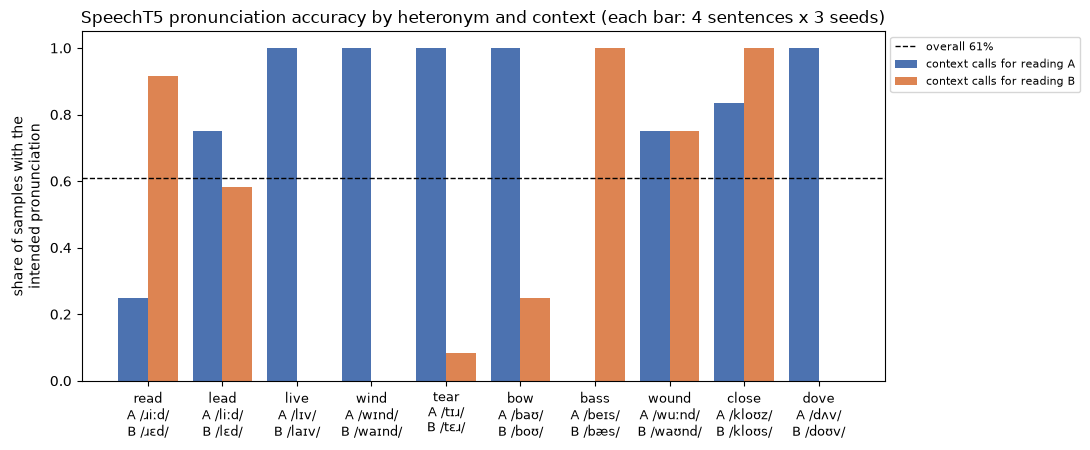

In [15]:
words = list(READINGS)
x = np.arange(len(words))
fig, ax = plt.subplots(figsize=(11, 4.6))
for offset, reading, color in [(-0.2, "A", "#4C72B0"), (0.2, "B", "#DD8452")]:
    ax.bar(x + offset, [acc.loc[w, reading] for w in words], width=0.4, color=color, label=f"context calls for reading {reading}")
ax.axhline(main.correct.mean(), color="black", lw=1, ls="--", label=f"overall {main.correct.mean():.0%}")
ax.set_xticks(x, [f"{w}\nA /{arpa_to_ipa(READINGS[w]['A'][0]).replace(' ', '')}/\nB /{arpa_to_ipa(READINGS[w]['B'][0]).replace(' ', '')}/" for w in words], fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of samples with the\nintended pronunciation")
ax.set_title("SpeechT5 pronunciation accuracy by heteronym and context (each bar: 4 sentences x 3 seeds)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.savefig("results/main_figure.png", dpi=150)
plt.show()

**Failure cases.** Every sentence whose majority prediction is not the intended reading, with the phonemes the recogniser heard in the target window for each seed.

In [16]:
heard = main.groupby("sentence_id").target_phones.agg(" | ".join).rename("heard (seed 0 | 1 | 2)")
failures = sentence_major[sentence_major.majority != sentence_major.reading].merge(data[["sentence_id", "text", "ipa"]]).join(heard, on="sentence_id")
print(len(failures), "of 80 sentences")
failures[["sentence_id", "text", "ipa", "heard (seed 0 | 1 | 2)", "majority"]]

31 of 80 sentences


,sentence_id,text,ipa,heard (seed 0 | 1 | 2),majority
0,bass_1A,He played a bass in the band.,b eɪ s,b æ s | b æ s | b æ s,B
1,bass_2A,She sings bass in the choir.,b eɪ s,b æ s | b æ s | b æ s,B
2,bass_3A,The bass was loud in the song.,b eɪ s,b æ s | b æ s | b æ s,B
3,bass_4A,Turn the bass up on the speaker.,b eɪ s,b æ s | b æ s | b æ s,B
4,bow_1B,She tied a bow on the gift.,b oʊ,b aʊ | b aʊ | b aʊ,A
5,bow_2B,The archer drew his bow.,b oʊ,b aʊ | b ɛ l | b aʊ,A
6,bow_4B,She played the violin with a bow.,b oʊ,b aʊ | b aʊ l | b aʊ,A
7,close_2A,The store will close soon.,k l oʊ z,k l oʊ z s | k l oʊ z s | k l oʊ z,unclear
8,dove_1B,A boy dove into the pool.,d oʊ v,d ʌ v | d ʌ v | d ʌ v,A
9,dove_2B,The dog dove over the fence.,d oʊ v,d ʌ v | d ʌ v | d ɑː v,A


**What the failures show.**
- **A fixed default reading (24 of 40 pairs).** For *wind*, *dove* and *bass*, and for most *live*, *bow* and *read* pairs, the model says the same thing in both contexts, usually identically across all 3 seeds. Examples: /wɪnd/ in *Please wind the old clock*, /dʌv/ in *We dove into the lake*, /bæs/ in *She sings bass in the choir*, /ɹɛd/ in *I read the book every day*. The default is not tied to the A/B labelling: *read* and *bass* default to reading B.
- **Third pronunciations (most `unclear` samples).** Sometimes the model produces neither reading: /leɪd/ ("laid") for *lead*, /lɛv/ for *live*, /tɜː/ or /teɪ/ for *tear*, /wɪn/ for *wound* (the past tense of *wind* said like the noun *wind*). The evaluator records these ties as `unclear` instead of forcing a label. This is also why *live*, *tear* and *bow* show a context effect above 0 even though the intended reading B is almost never produced.
- **One evaluator artefact.** In *The store will close soon* the time window also catches the /s/ of *soon* (`k l oʊ z s`), which ties the two readings. The /z/ is there, so this is probably a correct pronunciation scored as `unclear`.
- **Words that do follow context.** *close* (context effect 0.83), *wound* (0.67), *lead* (0.5). For *close*, the model switches between /kloʊz/ and /kloʊs/ in 3 of 4 pairs.

**Audio spot-check.** Six clips (seed 0) for a human listener to compare with the automatic labels: one pair where the model ignores context (*read*) and two where it follows it (*lead*, *close*). They are also copied to `results/audio_examples/`.

In [17]:
os.makedirs("results/audio_examples", exist_ok=True)
for sentence_id in ["read_1A", "read_1B", "lead_1A", "lead_1B", "close_1A", "close_1B"]:
    r = main[(main.sentence_id == sentence_id) & (main.seed == 0)].iloc[0]
    print(f"{sentence_id}: {r.text}  intended /{r.ipa}/ | heard [{r.target_phones}] -> {'correct' if r.correct else 'WRONG'}")
    shutil.copy(f"{AUDIO_DIR}/{sentence_id}_s0.wav", f"results/audio_examples/{sentence_id}_s0.wav")
    display(Audio(f"{AUDIO_DIR}/{sentence_id}_s0.wav"))

read_1A: I read the book every day.  intended /ɹ iː d/ | heard [ɹ ɛ d] -> WRONG


read_1B: I read the book yesterday.  intended /ɹ ɛ d/ | heard [ɹ ɛ d] -> correct


lead_1A: He saw the lead singer.  intended /l iː d/ | heard [l iː] -> correct


lead_1B: He saw the lead pipe.  intended /l ɛ d/ | heard [l ɛ d] -> correct


close_1A: Please close the door.  intended /k l oʊ z/ | heard [k l oʊ z] -> correct


close_1B: Please stay close to the door.  intended /k l oʊ s/ | heard [k l oʊ s] -> correct


## 8. Internal representation analysis

**Which representation.** SpeechT5's text encoder is a bidirectional Transformer over characters, so every character position can attend to the whole sentence, cues to the right included. We take the 13 hidden states it exposes:
- **layer 0:** the input to the first Transformer layer (character embedding plus scaled positional encoding, layer-normalised). It is *non-contextual*.
- **layers 1–12:** the output of each Transformer layer. Layer 12 is what the decoder cross-attends to while generating speech.

**Alignment to the target word.** Because token `k+1` is character `k`, the target word's states are the tokens at `char_start+1 … char_end`. We average them into one 768-dimensional vector per sentence and layer. No audio is involved: the encoder is deterministic, and these are exactly the states that `generate_speech` uses.

**Probe and split.** The label is the intended reading (A/B). A/B mean different things for different words, so each probe is trained *within one heteronym*, using leave-one-pair-out cross-validation:
- the probe for a word is fit on that word's other 3 pairs (6 sentences, 3 per class) and tested on the held-out pair;
- both sentences of the held-out pair are always in the test fold, so a pair can never be split between train and test;
- each of the 40 pairs is held out once, which gives 80 test predictions per layer.

The probe is a **nearest-centroid** classifier: predict the class whose training mean is closer (Euclidean distance). It is linear and has no hyperparameters, so there is nothing to tune and no validation split. All 13 layers are reported; no layer is "selected".

**Baselines:** chance is 50%. **Layer 0** is the non-contextual control. A target's layer-0 vector depends only on its own characters and their *positions*. When the target sits at the same character position in both sentences of a pair, the two vectors are identical and the probe must give both the same label (exactly 1 of 2 correct). When the positions differ, layer 0 carries position information, which can correlate with the reading by accident (*The wind…* vs *Please wind…*). Layer 0 can therefore score somewhat above 50%. The comparison that matters is how much the later layers add on top of layer 0, measured on the same 80 sentences with an exact McNemar test.

In [18]:
def target_states(text, char_start, char_end):
    ids = processor(text=text, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        hidden = tts.speecht5.encoder(input_values=ids, output_hidden_states=True).hidden_states
    return np.stack([h[0, char_start + 1:char_end + 1].mean(0).numpy() for h in hidden])

probe_data = data[data.condition != "control"].reset_index(drop=True)
X = np.stack([target_states(r.text, r.char_start, r.char_end) for r in probe_data.itertuples()])  # (sentences, layers, 768)
y = probe_data.reading.to_numpy()
print("features:", X.shape, "| class counts:", probe_data.reading.value_counts().to_dict())

probe_rows = []
for layer in range(X.shape[1]):
    for word in READINGS:
        for held_out in probe_data[probe_data.word == word].pair_id.unique():
            train = np.where((probe_data.word == word) & (probe_data.pair_id != held_out))[0]
            test = np.where(probe_data.pair_id == held_out)[0]
            assert not set(probe_data.pair_id[train]) & set(probe_data.pair_id[test]) and sorted(y[train]) == ["A"] * 3 + ["B"] * 3
            predicted = NearestCentroid().fit(X[train, layer], y[train]).predict(X[test, layer])
            for i, p in zip(test, predicted):
                probe_rows.append(dict(layer=layer, word=word, sentence_id=probe_data.sentence_id[i], predicted=p, correct=p == y[i]))
probe = pd.DataFrame(probe_rows)
probe.to_csv("results/probe_results.csv", index=False)

layer_acc = probe.groupby("layer").correct.agg(["sum", "count", "mean"])
layer_acc["ci"] = [binomtest(int(k), int(n)).proportion_ci(method="wilson") for k, n in zip(layer_acc["sum"], layer_acc["count"])]
layer_acc["ci_low"], layer_acc["ci_high"] = [c.low for c in layer_acc.ci], [c.high for c in layer_acc.ci]

positions = probe_data.pivot(index="pair_id", columns="reading", values="char_start")
print((positions.A == positions.B).sum(), "of 40 pairs have the target at the same character position (identical layer-0 vectors)")
layer0, layer12 = (probe[probe.layer == l].set_index("sentence_id").correct for l in (0, 12))
only12, only0 = int((layer12 & ~layer0).sum()), int((layer0 & ~layer12).sum())
mcnemar_p = binomtest(only12, only12 + only0).pvalue
print(f"Layer 12 vs layer 0: {only12} sentences right only at layer 12, {only0} right only at layer 0 -> exact McNemar p = {mcnemar_p:.3f}")
layer_acc.drop(columns="ci").round(3).T

features: (80, 13, 768) | class counts: {'A': 40, 'B': 40}


16 of 40 pairs have the target at the same character position (identical layer-0 vectors)
Layer 12 vs layer 0: 20 sentences right only at layer 12, 8 right only at layer 0 -> exact McNemar p = 0.036


layer,0,1,2,3,4,5,6,7,8,9,10,11,12
sum,47.000,48.00,48.00,48.00,51.000,48.00,49.000,49.000,52.000,55.000,57.000,55.000,59.000
count,80.000,80.00,80.00,80.00,80.000,80.00,80.000,80.000,80.000,80.000,80.000,80.000,80.000
mean,0.588,0.60,0.60,0.60,0.638,0.60,0.612,0.612,0.650,0.688,0.712,0.688,0.738
ci_low,0.478,0.49,0.49,0.49,0.528,0.49,0.503,0.503,0.541,0.579,0.605,0.579,0.632
ci_high,0.689,0.70,0.70,0.70,0.734,0.70,0.712,0.712,0.745,0.778,0.800,0.778,0.821


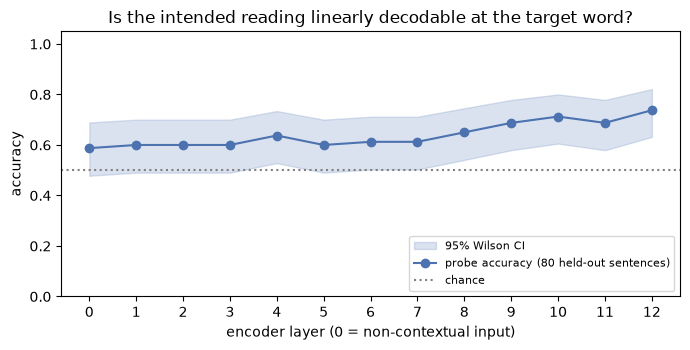

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.fill_between(layer_acc.index, layer_acc.ci_low, layer_acc.ci_high, color="#4C72B0", alpha=0.2, label="95% Wilson CI")
ax.plot(layer_acc.index, layer_acc["mean"], "o-", color="#4C72B0", label="probe accuracy (80 held-out sentences)")
ax.axhline(0.5, color="gray", ls=":", label="chance")
ax.set_xlabel("encoder layer (0 = non-contextual input)")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1.05)
ax.set_xticks(range(13))
ax.set_title("Is the intended reading linearly decodable at the target word?")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("results/probe_figure.png", dpi=150)
plt.show()

**Probe vs behaviour.** At the final encoder layer (12), is the intended reading decodable even in sentences where the model *spoke* the wrong pronunciation (majority over seeds)?

In [20]:
spoken = sentence_major.assign(spoken_correct=sentence_major.majority == sentence_major.reading)[["sentence_id", "spoken_correct"]]
last = probe[probe.layer == 12].merge(spoken, on="sentence_id")
print(last.groupby("spoken_correct").correct.agg(probe_correct="sum", sentences="count"))
probe[probe.layer == 12].groupby("word").correct.mean().reindex(list(READINGS)).to_frame("probe_acc_layer12").T

                probe_correct  sentences
spoken_correct                          
False                      23         31
True                       36         49


word,read,lead,live,wind,tear,bow,bass,wound,close,dove
probe_acc_layer12,0.875,0.625,0.75,1.0,0.625,0.5,0.5,1.0,0.75,0.75


**Interpretation.**
- Decodability climbs from 59% at layer 0 to 74% (95% CI 63–82%) at layer 12, with most of the rise in layers 8–12. On the same 80 sentences, layer 12 is right where layer 0 is wrong 20 times, and the reverse happens 8 times (exact McNemar p ≈ 0.04). Treat that p-value as approximate: the two sentences of a held-out pair share one probe, so they are not independent.
- Layer 0 sits above 50% because in 24 of 40 pairs the target is at a different character position, and position happens to correlate with the reading.
- At layer 12 the intended reading is decodable about equally often whether the model **spoke** the right pronunciation (36/49) or the wrong one (23/31). For *read* (7/8) and *wind* (8/8), the encoder separates the two contexts even though the spoken output hardly changes. The contextual information therefore reaches the target word's encoder states, but the decoder does not reliably turn it into the right sounds.
- **What this does not show.** The label is tied to the context words, so the probe may be picking up "the sentence contains *yesterday* / *clock*" rather than anything pronunciation-specific. Decodability does not mean the model *uses* this information, and with 8 test sentences per word the per-word numbers are very noisy.

In [21]:
metadata = {
    "tts_model": {"id": TTS_ID, "revision": TTS_REV, "vocoder": VOC_ID, "vocoder_revision": VOC_REV,
                  "speaker_xvector": f"{XVEC_ID}@{XVEC_REV}:spkrec-xvect/{SPEAKER}.npy",
                  "generate_speech_settings": {"threshold": 0.5, "minlenratio": 0.0, "maxlenratio": 20.0},
                  "seeds": SEEDS, "sample_rate": SR,
                  "stochasticity": "decoder prenet dropout is active at inference; torch.manual_seed(seed) before each generation"},
    "evaluator": {"phoneme_recogniser": f"{PHONE_ID}@{PHONE_REV}", "decoding": "greedy CTC",
                  "word_aligner": "torchaudio.pipelines.MMS_FA (forced_align)", "target_window_s": [-0.04, 0.02],
                  "decision": "Levenshtein distance over normalised phonemes; ties -> unclear (counted incorrect)"},
    "references": {"source": CMUDICT_URL},
    "dataset": {"heteronyms": list(READINGS), "pairs": len(PAIRS), "sentences": int((data.condition != "control").sum()), "controls": len(CONTROLS)},
    "results": {"control_accuracy": round(float(controls.correct.mean()), 4),
                "sample_accuracy": round(float(main.correct.mean()), 4),
                "sentence_majority_accuracy": round(float((sentence_major.majority == sentence_major.reading).mean()), 4),
                "unclear_samples": int((main.predicted == "unclear").sum()),
                "pair_outcomes": {k: int(v) for k, v in majority.outcome.value_counts().items()},
                "accuracy_by_word": {w: round(float(v), 4) for w, v in by_word["accuracy"].items()},
                "context_effect_by_word": {w: round(float(v), 4) for w, v in by_word["context effect"].items()},
                "probe_accuracy_by_layer": {int(k): round(float(v), 4) for k, v in layer_acc["mean"].items()},
                "probe_layer12_vs_layer0_mcnemar": {"only_layer12_correct": only12, "only_layer0_correct": only0, "p": round(float(mcnemar_p), 4)}},
    "audio_clips": {"loaded_from_cache": cached, "newly_generated": generated},
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "torchaudio": torchaudio.__version__,
                    "transformers": transformers.__version__, "scikit-learn": sklearn.__version__, "numpy": np.__version__,
                    "device": "cpu", "platform": platform.platform()},
}
with open("results/metadata.json", "w", encoding="utf8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print(json.dumps(metadata["results"], indent=1, ensure_ascii=False))

{
 "control_accuracy": 1.0,
 "sample_accuracy": 0.6083,
 "sentence_majority_accuracy": 0.6125,
 "unclear_samples": 21,
 "pair_outcomes": {
  "always A": 16,
  "both correct": 9,
  "always B": 8,
  "other": 7
 },
 "accuracy_by_word": {
  "read": 0.5833,
  "lead": 0.6667,
  "live": 0.5,
  "wind": 0.5,
  "tear": 0.5417,
  "bow": 0.625,
  "bass": 0.5,
  "wound": 0.75,
  "close": 0.9167,
  "dove": 0.5
 },
 "context_effect_by_word": {
  "read": 0.25,
  "lead": 0.5,
  "live": 0.3333,
  "wind": 0.0,
  "tear": 0.5,
  "bow": 0.3333,
  "bass": 0.0,
  "wound": 0.6667,
  "close": 0.8333,
  "dove": 0.0833
 },
 "probe_accuracy_by_layer": {
  "0": 0.5875,
  "1": 0.6,
  "2": 0.6,
  "3": 0.6,
  "4": 0.6375,
  "5": 0.6,
  "6": 0.6125,
  "7": 0.6125,
  "8": 0.65,
  "9": 0.6875,
  "10": 0.7125,
  "11": 0.6875,
  "12": 0.7375
 },
 "probe_layer12_vs_layer0_mcnemar": {
  "only_layer12_correct": 20,
  "only_layer0_correct": 8,
  "p": 0.0357
 }
}


## 9. Limitations and conclusion

**Findings (all numbers come from the outputs above).**
1. **Context helps only somewhat.** SpeechT5 produced the intended pronunciation in 146/240 samples (60.8%). At the sentence level, using the majority of 3 seeds, it was right in 49/80 (61%, 95% CI 50–71%). A context-blind model would score 50% on this balanced design. **H1 is only weakly supported.**
2. **The main behaviour is a per-word default.** 24 of 40 pairs got the same reading in both contexts, 9 switched correctly, none were reversed, and 7 were unclear or split. Context sensitivity varies a lot between words: *close* 0.83, *wound* 0.67, *lead* 0.50, but *wind* and *bass* 0.00 and *dove* 0.08. **H2 is supported.**
3. **The encoder carries the context.** The intended reading is linearly decodable from the target word's encoder states, rising from 59% at the non-contextual layer 0 to 74% at the final layer 12 (p ≈ 0.04 against layer 0). This held even in many sentences the model mispronounced. **H3 is supported, but weakly and only as decodability.** Our reading is that the information is present in the text encoder and the failure lies in how it is turned into speech, but this experiment does not prove that mechanism.

**Limitations.**
- **Automatic labels, not human listening.** Every pronunciation label comes from an independent phoneme recogniser. It was checked on 16 unambiguous control words (48/48 correct), but nobody listened to all 240 clips, and the analysis environment could not play audio. Listening to the failure table is the most useful next check.
- **Recogniser bias.** The recogniser might lean towards common pronunciations of whole words. The controls (*wined* → /waɪnd/, *drove* → /dɹoʊv/) suggest this bias is not strong.
- **Small, hand-written dataset.** 10 heteronyms with 4 pairs each. Most pairs differ by one or a few words, but some readings come with different syntax (noun vs verb), so context is not perfectly isolated from sentence structure. The results describe these sentences, not English heteronyms in general.
- **One model, one voice, default settings, 3 seeds.** A different speaker x-vector or other settings could change individual outcomes. Seeds of one sentence are correlated, so the sentence-level interval is the more honest one.
- **Fixed scoring window.** The window can pick up neighbouring sounds (*close soon*), and ties count as wrong, so accuracy is slightly conservative.
- **Weak probe.** 6 training sentences per fold, labels confounded with context words, and a position confound at layer 0.
- **Not tested.** Why particular defaults arise (for example, how often each reading appears in SpeechT5's audiobook training data) is a hypothesis, not a finding. The no-context condition was dropped because single-word inputs were unreliable (section 3d).